# Distribution and Quantile Functions
---

## Experiment: the CDF of a normal distribution.

P(X <= 1): 0.8413447460685429
P(X > 1): 0.15865525393145707
P(-1 < X <= 1): 0.6826894921370859


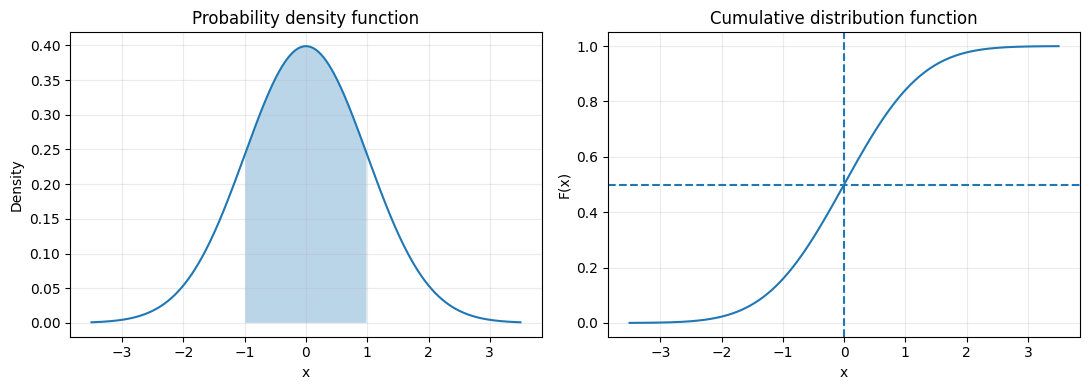

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Standard normal distribution.
distribution = norm(loc=0, scale=1)

x = np.linspace(-3.5, 3.5, 500)

pdf = distribution.pdf(x)
cdf = distribution.cdf(x)

print("P(X <= 1):", distribution.cdf(1))
print("P(X > 1):", distribution.sf(1))

interval_probability = (
    distribution.cdf(1) - distribution.cdf(-1)
)

print("P(-1 < X <= 1):", interval_probability)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Probability density function.
axes[0].plot(x, pdf)

mask = (x >= -1) & (x <= 1)

axes[0].fill_between(
    x[mask], pdf[mask], alpha=0.3
)

axes[0].set_title("Probability density function")
axes[0].set_xlabel("x")
axes[0].set_ylabel("Density")

# Cumulative distribution function.
axes[1].plot(x, cdf)
axes[1].axhline(0.5, linestyle="--")
axes[1].axvline(0, linestyle="--")

axes[1].set_title("Cumulative distribution function")
axes[1].set_xlabel("x")
axes[1].set_ylabel("F(x)")

for ax in axes:
    ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    "../../images/normal_pdf_cdf.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# Experiment: change the mean and standard deviation.
# How does the shape of the CDF change?

## Experiment: a discrete CDF and quantile function.

x      P(X=x)       F(x)
0      0.16807      0.16807
1      0.36015      0.52822
2      0.30870      0.83692
3      0.13230      0.96922
4      0.02835      0.99757
5      0.00243      1.00000
Q(0.25) = 1
Q(0.50) = 1
Q(0.75) = 2
Q(0.90) = 3


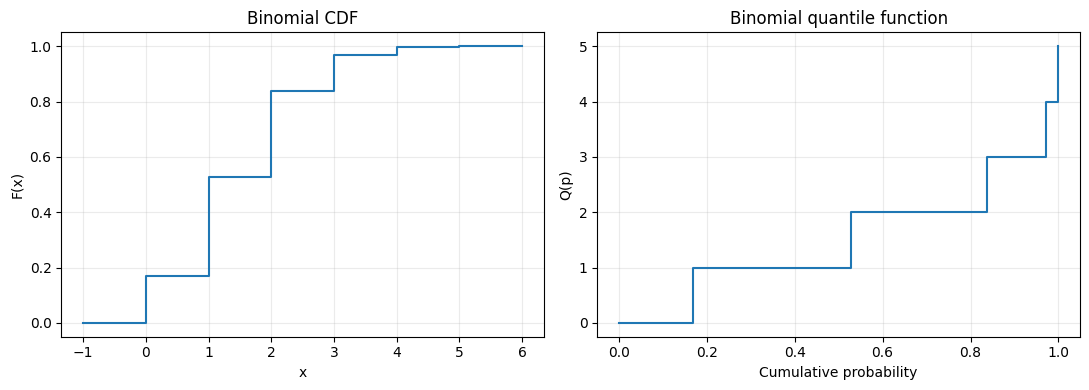

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

distribution = binom(n=5, p=0.3)

values = np.arange(0, 6)

print("x      P(X=x)       F(x)")

for x in values:
    print(
        f"{x}      "
        f"{distribution.pmf(x):.5f}      "
        f"{distribution.cdf(x):.5f}"
    )

# Quantiles of the same distribution.
probabilities = [0.25, 0.50, 0.75, 0.90]

for p in probabilities:
    q = distribution.ppf(p)
    print(f"Q({p:.2f}) = {q:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# CDF: a right-continuous step function.
x = np.arange(-1, 7)

axes[0].step(
    x, distribution.cdf(x), where="post"
)

axes[0].set_xlabel("x")
axes[0].set_ylabel("F(x)")
axes[0].set_title("Binomial CDF")

# Quantile function.
p = np.linspace(0.001, 0.999, 500)

axes[1].step(
    p, distribution.ppf(p), where="post"
)

axes[1].set_xlabel("Cumulative probability")
axes[1].set_ylabel("Q(p)")
axes[1].set_title("Binomial quantile function")

for ax in axes:
    ax.grid(alpha=0.25)

fig.tight_layout()

fig.savefig(
    "../../images/binomial_cdf_quantile.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# Experiment: change the success probability to 0.7.
# Compare the distributions and their quantiles.

## Experiment: checking the inverse relationship

In [5]:
import numpy as np
from scipy.stats import norm, binom

continuous = norm(loc=10, scale=2)
discrete = binom(n=5, p=0.3)

probabilities = [0.10, 0.25, 0.50, 0.90, 0.95]

print("Normal distribution:")

for p in probabilities:
    q = continuous.ppf(p)
    recovered = continuous.cdf(q)

    print(
        f"p={p:.2f}, "
        f"Q(p)={q:.4f}, "
        f"F(Q(p))={recovered:.4f}"
    )

print("\nBinomial distribution:")

for p in probabilities:
    q = discrete.ppf(p)
    recovered = discrete.cdf(q)

    print(
        f"p={p:.2f}, "
        f"Q(p)={q:.0f}, "
        f"F(Q(p))={recovered:.4f}"
    )

# Experiment: test other continuous and discrete
# probability distributions.

Normal distribution:
p=0.10, Q(p)=7.4369, F(Q(p))=0.1000
p=0.25, Q(p)=8.6510, F(Q(p))=0.2500
p=0.50, Q(p)=10.0000, F(Q(p))=0.5000
p=0.90, Q(p)=12.5631, F(Q(p))=0.9000
p=0.95, Q(p)=13.2897, F(Q(p))=0.9500

Binomial distribution:
p=0.10, Q(p)=0, F(Q(p))=0.1681
p=0.25, Q(p)=1, F(Q(p))=0.5282
p=0.50, Q(p)=1, F(Q(p))=0.5282
p=0.90, Q(p)=3, F(Q(p))=0.9692
p=0.95, Q(p)=3, F(Q(p))=0.9692


## Experiment: a mixed distribution.

In [7]:
import numpy as np

def mixed_cdf(x):
    if x < 0:
        return 0.0

    return 1 - 0.75 * np.exp(-x)


def mixed_quantile(p):
    if not 0 < p < 1:
        raise ValueError("p must lie strictly between 0 and 1")

    if p <= 0.25:
        return 0.0

    return -np.log((1 - p) / 0.75)


probabilities = [0.10, 0.25, 0.50, 0.90]

for p in probabilities:
    q = mixed_quantile(p)

    print(
        f"p={p:.2f}, "
        f"Q(p)={q:.4f}, "
        f"F(Q(p))={mixed_cdf(q):.4f}"
    )

# Experiment: change the point mass at zero.
# How do the median and other quantiles change?

p=0.10, Q(p)=0.0000, F(Q(p))=0.2500
p=0.25, Q(p)=0.0000, F(Q(p))=0.2500
p=0.50, Q(p)=0.4055, F(Q(p))=0.5000
p=0.90, Q(p)=2.0149, F(Q(p))=0.9000


## Experiment: inverse transform sampling.

Theoretical mean: 2.0
Sample mean: 1.9880522644675485
Theoretical median: 1.3862943611198906
Sample median: 1.3736074636303304


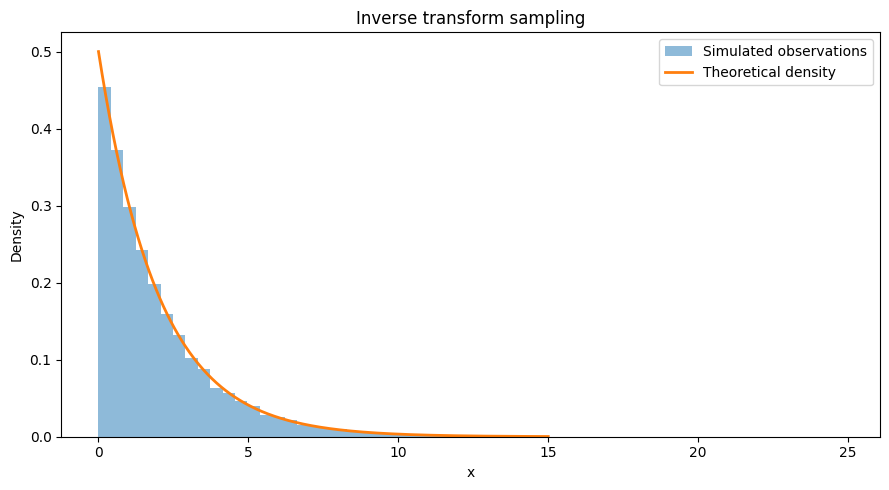

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import expon

rng = np.random.default_rng(2026)

rate = 0.5
sample_size = 50_000

# Generate uniform random observations.
u = rng.random(sample_size)

# Apply the exponential quantile function.
samples = -np.log1p(-u) / rate

distribution = expon(scale=1 / rate)

print("Theoretical mean:", distribution.mean())
print("Sample mean:", np.mean(samples))

print("Theoretical median:", distribution.ppf(0.5))
print("Sample median:", np.median(samples))

# Compare the simulated data with the density.
x = np.linspace(0, 15, 500)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    samples,
    bins=60,
    density=True,
    alpha=0.5,
    label="Simulated observations"
)

ax.plot(
    x,
    distribution.pdf(x),
    linewidth=2,
    label="Theoretical density"
)

ax.set_xlabel("x")
ax.set_ylabel("Density")
ax.set_title("Inverse transform sampling")
ax.legend()

fig.tight_layout()

fig.savefig(
    "../../images/inverse_transform_exponential.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# Experiment: change the rate parameter.
# Compare theoretical and empirical quantiles.

## Experiment: response-time probabilities and quantiles.

In [9]:
import numpy as np
from scipy.stats import lognorm

rng = np.random.default_rng(2026)

# Lognormal distribution parameters.
mu = 4.5
sigma = 0.6

distribution = lognorm(
    s=sigma,
    scale=np.exp(mu)
)

threshold = 150.0

# Probability of meeting the threshold.
within_threshold = distribution.cdf(threshold)

# Probability of exceeding the threshold.
exceedance_probability = distribution.sf(threshold)

# Theoretical response-time percentiles.
p50 = distribution.ppf(0.50)
p95 = distribution.ppf(0.95)
p99 = distribution.ppf(0.99)

print(f"P(X <= 150 ms): {within_threshold:.2%}")
print(f"P(X > 150 ms): {exceedance_probability:.2%}")

print(f"p50: {p50:.2f} ms")
print(f"p95: {p95:.2f} ms")
print(f"p99: {p99:.2f} ms")

# Simulate observations from the assumed model.
sample = rng.lognormal(
    mean=mu,
    sigma=sigma,
    size=10_000
)

empirical_exceedance = np.mean(sample > threshold)
empirical_p95 = np.quantile(sample, 0.95)

print(
    f"Empirical exceedance: "
    f"{empirical_exceedance:.2%}"
)

print(f"Empirical p95: {empirical_p95:.2f} ms")

# Experiment: increase sigma while keeping mu fixed.
# What happens to the upper percentiles?

P(X <= 150 ms): 80.26%
P(X > 150 ms): 19.74%
p50: 90.02 ms
p95: 241.51 ms
p99: 363.51 ms
Empirical exceedance: 19.82%
Empirical p95: 240.99 ms
